# Task 1: Data Preparation and Feature Engineering

### Setup: packages and versions

In [1]:
!pip install yfinance

In [2]:
import pandas as pd
import yfinance as yf
from datetime import date
import numpy as np
import matplotlib.pyplot as plt
import sklearn, scipy, matplotlib

print("pandas:", pd.__version__)
print("yfinance:", yf.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("matplotlib:", matplotlib.__version__)

pandas: 2.2.3
yfinance: 0.2.66
numpy: 2.4.6
scikit-learn: 1.6.1
SciPy: 1.16.3
matplotlib: 3.10.0


## 1.1 Ticker selection and data acquisition

In [3]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
tables = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})

In [4]:
sp500 = tables[0]

print(sp500.shape)
sp500.head()

(503, 8)


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [5]:
sp500 = sp500[["Symbol", "Security", "GICS Sector"]] .copy()

In [6]:
sp500["Symbol"] = sp500["Symbol"].str.replace(".", "-", regex=False)

In [7]:
sp500[sp500["Security"].str.contains("Berkshire")]

,Symbol,Security,GICS Sector
60,BRK-B,Berkshire Hathaway,Financials


In [8]:
retrieval_date = date(2026, 11, 19)

In [9]:
print("Retrieved on:", retrieval_date)
print("Number of companies:", len(sp500))

Retrieved on: 2026-11-19
Number of companies: 503


In [10]:
tickers = sp500["Symbol"].tolist()

In [11]:
prices = yf.download(
    tickers,
    start="2021-01-01",
    end="2025-01-01",
    auto_adjust=False
)

benchmark = yf.download(
    "^GSPC",
    start="2021-01-01",
    end="2025-01-01",
    auto_adjust=False
)

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'HONA', 'FDXF', 'VYLR', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed


In [12]:
print("Company data shape:", prices.shape)
print("Benchmark data shape:", benchmark.shape)
sp500[sp500["Symbol"].isin(["VYLR", "FDXF", "HONA", "Q", "SNDK"])]

Company data shape: (1005, 3018)
Benchmark data shape: (1005, 6)


,Symbol,Security,GICS Sector
192,FDXF,FedEx Freight,Industrials
233,HONA,Honeywell Aerospace,Industrials
379,Q,Qnity Electronics,Information Technology
402,SNDK,Sandisk,Information Technology
478,VYLR,Vylor,Consumer Staples


In [13]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
folder = "/content/drive/MyDrive/CRM_Coursework"
print("Folder ready:", folder)

Folder ready: /content/drive/MyDrive/CRM_Coursework


In [15]:
adj_close = prices["Adj Close"]
close = prices["Close"]
volume = prices["Volume"]

adj_close.to_csv(f"{folder}/adj_close_raw.csv")
close.to_csv(f"{folder}/close_raw.csv")
volume.to_csv(f"{folder}/volume_raw.csv")
benchmark.to_csv(f"{folder}/benchmark_raw.csv")
sp500.to_csv(f"{folder}/sp500_constituents.csv", index=False)

## 1.2 Data validation and alignment

In [16]:
missing = adj_close.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Companies with missing data:", len(missing))
print("Missing values in Adj Close:", adj_close.isna().sum().sum())
print("Missing values in Close:", close.isna().sum().sum())
print("Missing values in Volume:", volume.isna().sum().sum())
missing

Companies with missing data: 15
Missing values in Adj Close: 9211
Missing values in Close: 9211
Missing values in Volume: 9211


,0
Ticker,
FDXF,1005
Q,1005
HONA,1005
SNDK,1005
VYLR,1005
GEV,812
SOLV,811
RDDT,808
VLTO,692


In [17]:
results = []

for ticker in missing.index:
    first_date = adj_close[ticker].dropna().index.min()

    if pd.isna(first_date):
        reason = "No price data in study period"
    else:
        reason = "Started trading after study start"

    results.append({
        "Ticker": ticker,
        "Missing days": missing[ticker],
        "First date with data": first_date,
        "Reason": reason,
        "Rule": "Keep only companies with complete data for 2021-2024"
    })

exclusion_log = pd.DataFrame(results)
exclusion_log

,Ticker,Missing days,First date with data,Reason,Rule
0,FDXF,1005,NaT,No price data in study period,Keep only companies with complete data for 202...
1,Q,1005,NaT,No price data in study period,Keep only companies with complete data for 202...
2,HONA,1005,NaT,No price data in study period,Keep only companies with complete data for 202...
3,SNDK,1005,NaT,No price data in study period,Keep only companies with complete data for 202...
4,VYLR,1005,NaT,No price data in study period,Keep only companies with complete data for 202...
5,GEV,812,2024-03-27,Started trading after study start,Keep only companies with complete data for 202...
6,SOLV,811,2024-03-26,Started trading after study start,Keep only companies with complete data for 202...
7,RDDT,808,2024-03-21,Started trading after study start,Keep only companies with complete data for 202...
8,VLTO,692,2023-10-04,Started trading after study start,Keep only companies with complete data for 202...
9,GEHC,492,2022-12-15,Started trading after study start,Keep only companies with complete data for 202...


In [18]:
keep = [t for t in adj_close.columns if t not in missing.index]

adj_close_clean = adj_close[keep]
close_clean = close[keep]
volume_clean = volume[keep]

print("Companies kept:", len(keep))
print("Any missing left?", adj_close_clean.isna().sum().sum() + close_clean.isna().sum().sum() + volume_clean.isna().sum().sum())

exclusion_log.to_csv(f"{folder}/exclusion_log.csv", index=False)

Companies kept: 488
Any missing left? 0


In [19]:
print("Number of dates:", len(adj_close_clean.index))
print("Number of unique dates:", len(adj_close_clean.index.unique()))

Number of dates: 1005
Number of unique dates: 1005


In [20]:
print("Prices zero or below (Adj Close):", (adj_close_clean <= 0).sum().sum())
print("Prices zero or below (Close):", (close_clean <= 0).sum().sum())
print("Negative volume:", (volume_clean < 0).sum().sum())
print("Days with zero volume:", (volume_clean == 0).sum().sum())

Prices zero or below (Adj Close): 0
Prices zero or below (Close): 0
Negative volume: 0
Days with zero volume: 451


In [21]:
zero_volume = (volume_clean == 0).sum()
zero_volume = zero_volume[zero_volume > 0].sort_values(ascending=False)

print("Companies with zero-volume days:", len(zero_volume))
zero_volume

Companies with zero-volume days: 2


,0
Ticker,
SW,424
FERG,27


In [22]:
zero_by_date = (volume_clean == 0).sum(axis=1)
zero_by_date = zero_by_date[zero_by_date > 0].sort_values(ascending=False)

print("Dates with zero volume:", len(zero_by_date))
zero_by_date.head(10)

Dates with zero volume: 435


,0
Date,
2021-02-03,2
2021-02-22,2
2021-03-01,2
2021-01-12,2
2021-01-13,2
2021-02-16,2
2021-02-09,2
2021-01-21,2
2021-01-22,2


In [23]:
for ticker in zero_volume.index:
    zero_days = volume_clean[ticker][volume_clean[ticker] == 0]
    print(ticker, "| zero days:", len(zero_days),
          "| first:", zero_days.index.min(),
          "| last:", zero_days.index.max())

SW | zero days: 424 | first: 2021-01-05 00:00:00 | last: 2024-07-05 00:00:00
FERG | zero days: 27 | first: 2021-01-07 00:00:00 | last: 2021-03-05 00:00:00


In [24]:
zero_volume_results = []

for ticker in zero_volume.index:
    zero_days = volume_clean[ticker][volume_clean[ticker] == 0]
    zero_volume_results.append({
        "Ticker": ticker,
        "Missing days": 0,
        "First date with data": adj_close[ticker].dropna().index.min(),
        "Zero-volume days": len(zero_days),
        "Last zero-volume date": zero_days.index.max(),
        "Reason": "Zero volume on many days: no reliable trading data before the last zero-volume date",
        "Rule": "Keep only companies with reliable trading data for 2021-2024"
    })

exclusion_log = pd.DataFrame(results + zero_volume_results)
excluded = exclusion_log["Ticker"].tolist()

keep = [t for t in adj_close.columns if t not in excluded]
adj_close_clean = adj_close[keep]
close_clean = close[keep]
volume_clean = volume[keep]

print("Companies kept:", len(keep))
print("Zero-volume days left:", (volume_clean == 0).sum().sum())

exclusion_log.to_csv(f"{folder}/exclusion_log.csv", index=False)
exclusion_log

Companies kept: 486
Zero-volume days left: 0


,Ticker,Missing days,First date with data,Reason,Rule,Zero-volume days,Last zero-volume date
0,FDXF,1005,NaT,No price data in study period,Keep only companies with complete data for 202...,NaN,NaT
1,Q,1005,NaT,No price data in study period,Keep only companies with complete data for 202...,NaN,NaT
2,HONA,1005,NaT,No price data in study period,Keep only companies with complete data for 202...,NaN,NaT
3,SNDK,1005,NaT,No price data in study period,Keep only companies with complete data for 202...,NaN,NaT
4,VYLR,1005,NaT,No price data in study period,Keep only companies with complete data for 202...,NaN,NaT
5,GEV,812,2024-03-27,Started trading after study start,Keep only companies with complete data for 202...,NaN,NaT
6,SOLV,811,2024-03-26,Started trading after study start,Keep only companies with complete data for 202...,NaN,NaT
7,RDDT,808,2024-03-21,Started trading after study start,Keep only companies with complete data for 202...,NaN,NaT
8,VLTO,692,2023-10-04,Started trading after study start,Keep only companies with complete data for 202...,NaN,NaT
9,GEHC,492,2022-12-15,Started trading after study start,Keep only companies with complete data for 202...,NaN,NaT


In [25]:
nvda = pd.concat([close_clean["NVDA"].rename("Close"),
                  adj_close_clean["NVDA"].rename("Adj Close"),
                  volume_clean["NVDA"].rename("Volume")], axis=1)

nvda.loc["2024-06-04":"2024-06-12"]

,Close,Adj Close,Volume
Date,,,
2024-06-04,116.436996,116.105919,403324000
2024-06-05,122.440002,122.091881,528402000
2024-06-06,120.998001,120.653961,664696000
2024-06-07,120.888000,120.544296,412386000
2024-06-10,121.790001,121.443718,313434100
2024-06-11,120.910004,120.576126,222551200
2024-06-12,125.199997,124.854279,299595000


In [26]:
close_change = close_clean.pct_change(fill_method=None)

big_drops = (close_change < -0.5).sum()
big_drops = big_drops[big_drops > 0]

print("Companies with a one-day Close drop over 50%:", len(big_drops))
big_drops

Companies with a one-day Close drop over 50%: 1


,0
Ticker,
GL,1


In [27]:
print(close_change["GL"][close_change["GL"] < -0.5])
close_clean["GL"].loc["2024-04-08":"2024-04-18"]

Date
2024-04-11   -0.531402
Name: GL, dtype: float64


,GL
Date,
2024-04-08,107.849998
2024-04-09,107.610001
2024-04-10,104.930000
2024-04-11,49.169998
2024-04-12,59.090000
2024-04-15,55.810001
2024-04-16,59.970001
2024-04-17,63.230000
2024-04-18,65.000000


## 1.3 Weekly return and weekly beta

### 1.3.1 Mean weekly return

In [28]:
weekly_prices = adj_close_clean.resample("W-FRI").last()
market_weekly_prices = benchmark["Adj Close"]["^GSPC"].resample("W-FRI").last()

print("First weeks:", weekly_prices.index[:2])
print("Last weeks:", weekly_prices.index[-2:])

First weeks: DatetimeIndex(['2021-01-08', '2021-01-15'], dtype='datetime64[ns]', name='Date', freq='W-FRI')
Last weeks: DatetimeIndex(['2024-12-27', '2025-01-03'], dtype='datetime64[ns]', name='Date', freq='W-FRI')


In [29]:
weekly_prices = weekly_prices.loc[:"2024-12-27"]
market_weekly_prices = market_weekly_prices.loc[:"2024-12-27"]

print("Last week now:", weekly_prices.index[-1])
print("Number of weekly prices:", len(weekly_prices))

Last week now: 2024-12-27 00:00:00
Number of weekly prices: 208


In [30]:
weekly_returns = weekly_prices.pct_change(fill_method=None)
market_weekly_returns = market_weekly_prices.pct_change(fill_method=None)

weekly_returns = weekly_returns.dropna(how="all")
market_weekly_returns = market_weekly_returns.dropna()

print("Number of weekly returns:", len(weekly_returns))
print("First return week:", weekly_returns.index[0])
print("Missing weekly returns:", weekly_returns.isna().sum().sum())

Number of weekly returns: 207
First return week: 2021-01-15 00:00:00
Missing weekly returns: 0


In [31]:
mean_weekly_return = weekly_returns.mean()
print(mean_weekly_return.describe())

p1 = weekly_prices["AAPL"].loc["2021-01-08"]
p2 = weekly_prices["AAPL"].loc["2021-01-15"]
print("AAPL return by hand:", p2 / p1 - 1)
print("AAPL return from code:", weekly_returns["AAPL"].loc["2021-01-15"])

count    486.000000
mean       0.002857
std        0.002652
min       -0.004468
25%        0.001182
50%        0.002619
75%        0.004207
max        0.017772
dtype: float64
AAPL return by hand: -0.03718280660142492
AAPL return from code: -0.03718280660142492


## 1.3.2 Weekly beta

In [32]:
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    """
    weekly_returns: DataFrame with weeks as rows and shares as columns.
    market_returns: Series of benchmark returns indexed by week.
    """
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")

    results = []

    for share in weekly_returns.columns:
        paired = pd.concat(
            [weekly_returns[share].rename("share"),
             market_returns.rename("market")],
            axis=1
        ).replace([np.inf, -np.inf], np.nan).dropna()

        variance = paired["market"].var(ddof=1)
        beta = np.nan

        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(
        results, columns=["Share", "Beta", "Paired_weeks"]
    ).set_index("Share")

In [33]:
print("Week labels identical:", (weekly_returns.index == market_weekly_returns.index).all())

beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns)

print("Paired weeks (min, max):", beta_df["Paired_weeks"].min(), beta_df["Paired_weeks"].max())
beta_df["Beta"].describe()

Week labels identical: True
Paired weeks (min, max): 207 207


,Beta
count,486.000000
mean,0.973695
std,0.407339
min,0.055453
25%,0.666599
50%,0.950609
75%,1.179538
max,3.778560


In [34]:
print("Lowest betas:")
print(beta_df.sort_values("Beta").head())
print("Highest betas:")
print(beta_df.sort_values("Beta").tail())

Lowest betas:
           Beta  Paired_weeks
Share                        
GIS    0.055453           207
SJM    0.175578           207
MRK    0.198287           207
BMY    0.225013           207
KHC    0.227169           207
Highest betas:
           Beta  Paired_weeks
Share                        
TWLO   2.073379           207
NVDA   2.125953           207
COHR   2.139305           207
XYZ    2.504520           207
CVNA   3.778560           207


In [35]:
aapl_beta = weekly_returns["AAPL"].cov(market_weekly_returns) / market_weekly_returns.var()
print("AAPL beta by hand:", aapl_beta)
print("AAPL beta from function:", beta_df.loc["AAPL", "Beta"])

AAPL beta by hand: 1.1748355684813965
AAPL beta from function: 1.1748355684813965


## 1.4 Adapted RFM calculations

### Observation date and busy-day flags

In [36]:
observation_date = volume_clean.index.max()
print("Observation date:", observation_date)

avg_20 = volume_clean.shift(1).rolling(20).mean()
threshold = 2 * avg_20
events = volume_clean > threshold

print("Days without a threshold (AAPL):", threshold["AAPL"].isna().sum())
print("Total busy days across all companies:", events.sum().sum())

Observation date: 2024-12-31 00:00:00
Days without a threshold (AAPL): 20
Total busy days across all companies: 18280


### 1.4.1 Recency

In [37]:
recency_results = []

for ticker in events.columns:
    event_days = events[ticker][events[ticker]]

    if len(event_days) > 0:
        last_event = event_days.index.max()
        recency = (observation_date - last_event).days
    else:
        last_event = None
        recency = np.nan

    recency_results.append({
        "Share": ticker,
        "Last_event": last_event,
        "Recency": recency
    })

recency_df = pd.DataFrame(recency_results).set_index("Share")

print("Companies with no busy day:", recency_df["Recency"].isna().sum())
print("Busy day on the observation date (R = 0):", (recency_df["Recency"] == 0).sum())
recency_df["Recency"].describe()

Companies with no busy day: 0
Busy day on the observation date (R = 0): 0


,Recency
count,486.000000
mean,20.407407
std,21.342438
min,4.000000
25%,11.000000
50%,11.000000
75%,14.750000
max,222.000000


In [38]:
print("Companies whose last busy day was 20 Dec 2024:", (recency_df["Recency"] == 11).sum())

Companies whose last busy day was 20 Dec 2024: 353


### 1.4.2 Frequency

In [39]:
last_60 = events.tail(60)
frequency = last_60.sum()

print("Window starts:", last_60.index[0])
print("Window ends:", last_60.index[-1])
print("Sessions in window:", len(last_60))
print("Every day in window has a 20-day baseline:", threshold.tail(60).notna().all().all())
frequency.describe()

Window starts: 2024-10-07 00:00:00
Window ends: 2024-12-31 00:00:00
Sessions in window: 60
Every day in window has a 20-day baseline: True


,0
count,486.000000
mean,2.989712
std,1.330800
min,0.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,8.000000


In [40]:
print("Smallest Recency among companies with F = 0:", recency_df["Recency"][frequency == 0].min())

Smallest Recency among companies with F = 0: 91


### 1.4.3 Monetary

In [41]:
close_60 = close_clean.tail(60)
volume_60 = volume_clean.tail(60)

monetary = (close_60 * volume_60).sum()

print("Same window as Frequency:", close_60.index[0], "to", close_60.index[-1])
print((monetary / 1e9).describe())

aapl_day = close_60["AAPL"].iloc[-1] * volume_60["AAPL"].iloc[-1]
print("AAPL traded value on 31 Dec 2024 (USD):", aapl_day)

Same window as Frequency: 2024-10-07 00:00:00 to 2024-12-31 00:00:00
count     486.000000
mean       39.404192
std       129.138833
min         1.297483
25%        10.195173
50%        16.683822
75%        32.276893
max      1847.697379
dtype: float64
AAPL traded value on 31 Dec 2024 (USD): 9886756821.70868


### Feature table

In [42]:
features = pd.DataFrame({
    "Mean_weekly_return": mean_weekly_return,
    "Beta": beta_df["Beta"],
    "Weeks": beta_df["Paired_weeks"],
    "Last_event": recency_df["Last_event"],
    "Recency": recency_df["Recency"],
    "Frequency": frequency,
    "Monetary": monetary
})

sectors = sp500.set_index("Symbol")[["Security", "GICS Sector"]]
features = sectors.join(features, how="inner")
features.index.name = "Share"
features["Observation_date"] = observation_date

print("Feature table shape:", features.shape)
features.to_csv(f"{folder}/feature_table.csv")

print(features.sort_values("Monetary", ascending=False).head())

Feature table shape: (486, 10)
          Security             GICS Sector  Mean_weekly_return      Beta  \
Share                                                                      
TSLA   Tesla, Inc.  Consumer Discretionary            0.005275  2.045761   
NVDA        Nvidia  Information Technology            0.013624  2.125953   
AAPL    Apple Inc.  Information Technology            0.003930  1.174836   
MSFT     Microsoft  Information Technology            0.003982  1.128575   
AMZN        Amazon  Consumer Discretionary            0.002681  1.386667   

       Weeks Last_event  Recency  Frequency      Monetary Observation_date  
Share                                                                       
TSLA     207 2024-11-11       50          5  1.847697e+12       2024-12-31  
NVDA     207 2024-05-23      222          0  1.825337e+12       2024-12-31  
AAPL     207 2024-12-20       11          2  6.233034e+11       2024-12-31  
MSFT     207 2024-12-20       11          2  5.3489

## 1.5 Metric interpretation and supporting evidence

In [43]:
share = "AAPL"

manual_avg = volume_clean[share].loc[:"2024-12-19"].tail(20).mean()
print("20-day average before 20 Dec, by hand:", manual_avg)
print("20-day average from code:", avg_20[share].loc["2024-12-20"])
print("Threshold (2 x average):", 2 * manual_avg)
print("Volume on 20 Dec:", volume_clean[share].loc["2024-12-20"])

example = pd.DataFrame({
    "Volume": volume_60[share],
    "Threshold": threshold[share].tail(60),
    "Event": events[share].tail(60)
})
print("\nBusy days in the last 60 sessions:")
print(example[example["Event"]])

last_event = features.loc[share, "Last_event"]
print("\nRecency:", observation_date.date(), "-", last_event.date(), "=", (observation_date - last_event).days, "days")
print("Frequency:", example["Event"].sum(), "busy days")

daily_value = close_60[share] * volume_60[share]
print("\nFirst 3 daily Close x Volume values:")
print((daily_value.head(3) / 1e9).round(2), "(USD bn)")
print("Monetary (sum of 60 days):", daily_value.sum())
print("Matches feature table:", features.loc[share, "Monetary"])

20-day average before 20 Dec, by hand: 45004605.0
20-day average from code: 45004605.0
Threshold (2 x average): 90009210.0
Volume on 20 Dec: 147495300

Busy days in the last 60 sessions:
               Volume   Threshold  Event
Date                                    
2024-11-25   90152800  87641480.0   True
2024-12-20  147495300  90009210.0   True

Recency: 2024-12-31 - 2024-12-20 = 11 days
Frequency: 2 busy days

First 3 daily Close x Volume values:
Date
2024-10-07    8.76
2024-10-08    7.19
2024-10-09    7.71
Name: AAPL, dtype: float64 (USD bn)
Monetary (sum of 60 days): 623303377706.5842
Matches feature table: 623303377706.5842


In [44]:
summary_cols = ["Mean_weekly_return", "Beta", "Recency", "Frequency", "Monetary"]

summary_data = features[summary_cols].copy()
summary_data["Mean_weekly_return"] = summary_data["Mean_weekly_return"] * 100
summary_data["Monetary"] = summary_data["Monetary"] / 1e9
summary_data = summary_data.rename(columns={
    "Mean_weekly_return": "Mean weekly return (%)",
    "Monetary": "Monetary (USD bn)"
})

summary = summary_data.describe().T
summary["skew"] = summary_data.skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
Mean weekly return (%),486.0,0.29,0.27,-0.45,0.12,0.26,0.42,1.78,0.87
Beta,486.0,0.97,0.41,0.06,0.67,0.95,1.18,3.78,1.10
Recency,486.0,20.41,21.34,4.00,11.00,11.00,14.75,222.00,3.65
Frequency,486.0,2.99,1.33,0.00,2.00,3.00,4.00,8.00,0.42
Monetary (USD bn),486.0,39.40,129.14,1.30,10.20,16.68,32.28,1847.70,11.68


### Validation and inclusion summary

In [45]:
checks = []

checks.append({"Check": "Duplicate trading dates",
               "Result": len(adj_close_clean.index) - len(adj_close_clean.index.unique())})
checks.append({"Check": "Missing values in Adj Close, Close and Volume",
               "Result": adj_close_clean.isna().sum().sum() + close_clean.isna().sum().sum() + volume_clean.isna().sum().sum()})
checks.append({"Check": "Prices zero or below",
               "Result": (adj_close_clean <= 0).sum().sum() + (close_clean <= 0).sum().sum()})
checks.append({"Check": "Volume zero or below",
               "Result": (volume_clean <= 0).sum().sum()})
checks.append({"Check": "Share and benchmark week labels identical",
               "Result": (weekly_returns.index == market_weekly_returns.index).all()})
checks.append({"Check": "Fewest aligned weeks for any share",
               "Result": beta_df["Paired_weeks"].min()})
checks.append({"Check": "Most aligned weeks for any share",
               "Result": beta_df["Paired_weeks"].max()})

checks.append({"Check": "Sessions in the 60-session window",
               "Result": len(last_60)})
checks.append({"Check": "Every day in window has a 20-day baseline",
               "Result": threshold.tail(60).notna().all().all()})
checks.append({"Check": "Frequency and Monetary use the same dates",
               "Result": (last_60.index == close_60.index).all()})

checks.append({"Check": "Shares with no busy day (R missing)",
               "Result": recency_df["Recency"].isna().sum()})
checks.append({"Check": "Shares with a busy day on the observation date (R = 0)",
               "Result": (recency_df["Recency"] == 0).sum()})
checks.append({"Check": "Smallest Recency among shares with F = 0 (window is 85 days)",
               "Result": recency_df["Recency"][frequency == 0].min()})

validation_table = pd.DataFrame(checks)
validation_table.to_csv(f"{folder}/validation_checks.csv", index=False)
validation_table

,Check,Result
0,Duplicate trading dates,0
1,"Missing values in Adj Close, Close and Volume",0
2,Prices zero or below,0
3,Volume zero or below,0
4,Share and benchmark week labels identical,True
5,Fewest aligned weeks for any share,207
6,Most aligned weeks for any share,207
7,Sessions in the 60-session window,60
8,Every day in window has a 20-day baseline,True
9,Frequency and Monetary use the same dates,True


In [46]:
baseline_check = []

for share in ["AAPL", "MSFT", "TSLA", "GL", "XOM"]:
    by_hand = volume_clean[share].loc[:"2024-12-19"].tail(20).mean()
    by_code = avg_20[share].loc["2024-12-20"]
    baseline_check.append({
        "Share": share,
        "20-day average by hand": round(by_hand, 2),
        "20-day average from code": round(by_code, 2),
        "Match": round(by_hand, 2) == round(by_code, 2)
    })

pd.DataFrame(baseline_check)

,Share,20-day average by hand,20-day average from code,Match
0,AAPL,45004605.0,45004605.0,True
1,MSFT,21397685.0,21397685.0,True
2,TSLA,86925185.0,86925185.0,True
3,GL,779270.0,779270.0,True
4,XOM,16986705.0,16986705.0,True


In [47]:

print("Rows in exclusion log:", len(exclusion_log))

steps = []
remaining = len(sp500)
steps.append({"Step": "S&P 500 tickers from Wikipedia", "Excluded": 0, "Remaining": remaining, "Tickers": ""})

for reason, group in exclusion_log.groupby("Reason"):
    remaining = remaining - len(group)
    steps.append({
        "Step": reason,
        "Excluded": len(group),
        "Remaining": remaining,
        "Tickers": group["Ticker"].tolist()
    })

inclusion_log = pd.DataFrame(steps)
inclusion_log.to_csv(f"{folder}/inclusion_log.csv", index=False)
common = features.dropna(subset=["Mean_weekly_return", "Beta", "Recency", "Frequency", "Monetary"])
print("Shares in the common set used for all clustering:", len(common))
common.to_csv(f"{folder}/feature_table_common.csv")

inclusion_log

Rows in exclusion log: 17
Shares in the common set used for all clustering: 486


,Step,Excluded,Remaining,Tickers
0,S&P 500 tickers from Wikipedia,0,503,
1,No price data in study period,5,498,"[FDXF, Q, HONA, SNDK, VYLR]"
2,Started trading after study start,10,488,"[GEV, SOLV, RDDT, VLTO, GEHC, CEG, HOOD, APP, ..."
3,Zero volume on many days: no reliable trading ...,2,486,"[SW, FERG]"


# Task 2: Stock Segmentation and Sensitivity Analysis

## 2.1 Feature preparation

In [48]:
features = pd.read_csv(f"{folder}/feature_table_common.csv", index_col="Share")
print("Shares:", features.shape[0])

Shares: 486


In [49]:
risk = features[["Mean_weekly_return", "Beta"]].copy()
activity = features[["Recency", "Frequency", "Monetary"]].copy()

print("Risk/return skew:")
print(risk.skew().round(2))
print("\nTrading activity skew:")
print(activity.skew().round(2))

Risk/return skew:
Mean_weekly_return    0.87
Beta                  1.10
dtype: float64

Trading activity skew:
Recency       3.65
Frequency     0.42
Monetary     11.68
dtype: float64


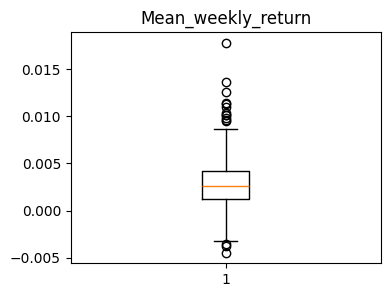

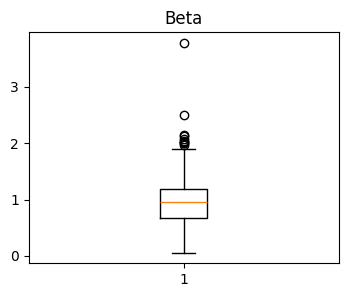

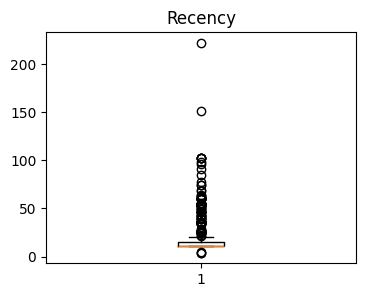

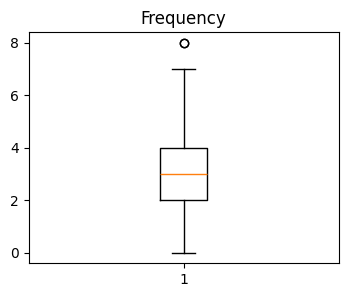

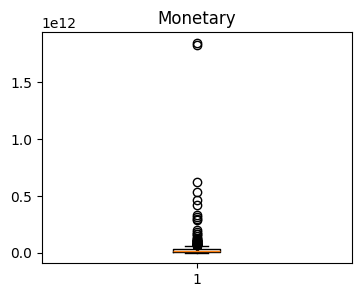

In [50]:
for col in ["Mean_weekly_return", "Beta", "Recency", "Frequency", "Monetary"]:
    plt.figure(figsize=(4, 3))
    plt.boxplot(features[col])
    plt.title(col)
    plt.show()

In [51]:
print("Skew before and after log1p:")
print("Monetary:", round(activity["Monetary"].skew(), 2), "->", round(np.log1p(activity["Monetary"]).skew(), 2))
print("Recency:", round(activity["Recency"].skew(), 2), "->", round(np.log1p(activity["Recency"]).skew(), 2))

Skew before and after log1p:
Monetary: 11.68 -> 1.08
Recency: 3.65 -> 1.58


In [52]:
from sklearn.preprocessing import StandardScaler

activity_t = activity.copy()
activity_t["Monetary"] = np.log1p(activity_t["Monetary"])
activity_t["Recency"] = np.log1p(activity_t["Recency"])

risk_scaled = pd.DataFrame(StandardScaler().fit_transform(risk),
                           index=risk.index, columns=risk.columns)
activity_scaled = pd.DataFrame(StandardScaler().fit_transform(activity_t),
                               index=activity_t.index, columns=activity_t.columns)

print("Risk/return after scaling (mean, then std):")
print(risk_scaled.mean(axis=0).round(2))
print(risk_scaled.std(axis=0).round(2))
print("\nTrading activity after scaling (mean, then std):")
print(activity_scaled.mean(axis=0).round(2))
print(activity_scaled.std(axis=0).round(2))

Risk/return after scaling (mean, then std):
Mean_weekly_return    0.0
Beta                 -0.0
dtype: float64
Mean_weekly_return    1.0
Beta                  1.0
dtype: float64

Trading activity after scaling (mean, then std):
Recency      0.0
Frequency   -0.0
Monetary    -0.0
dtype: float64
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


## 2.2 Agglomerative (Ward) clustering

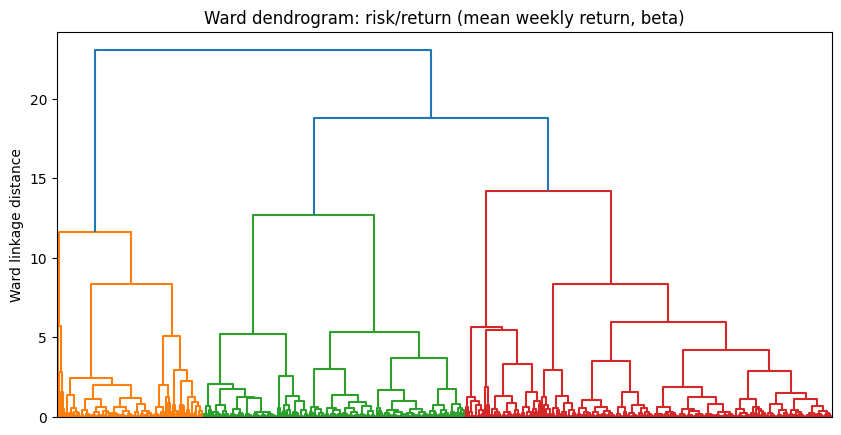

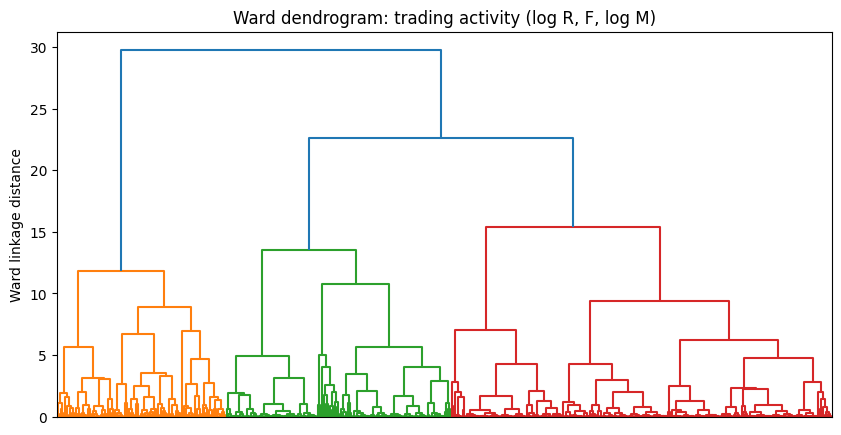

In [53]:
from scipy.cluster.hierarchy import linkage, dendrogram

ward_risk = linkage(risk_scaled, method="ward")
ward_activity = linkage(activity_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(ward_risk, no_labels=True)
plt.title("Ward dendrogram: risk/return (mean weekly return, beta)")
plt.ylabel("Ward linkage distance")
plt.show()

plt.figure(figsize=(10, 5))
dendrogram(ward_activity, no_labels=True)
plt.title("Ward dendrogram: trading activity (log R, F, log M)")
plt.ylabel("Ward linkage distance")
plt.show()

In [54]:
from scipy.cluster.hierarchy import cut_tree
from sklearn.metrics import silhouette_score

def ward_table(linkage_matrix, X):
    rows = []
    for k in range(2, 9):
        labels = cut_tree(linkage_matrix, n_clusters=k).ravel()
        sizes = []
        for group in range(k):
            sizes.append((labels == group).sum())
        rows.append({
            "k": k,
            "Silhouette": round(silhouette_score(X, labels), 3),
            "Smallest cluster": pd.Series(sizes).min(),
            "Cluster sizes": sizes
        })
    return pd.DataFrame(rows).set_index("k")

print("Ward, risk/return:")
print(ward_table(ward_risk, risk_scaled))
print("\nWard, trading activity:")
print(ward_table(ward_activity, activity_scaled))

Ward, risk/return:
   Silhouette  Smallest cluster                     Cluster sizes
k                                                                
2       0.339                92                         [394, 92]
3       0.274                92                    [230, 164, 92]
4       0.282                48                [182, 164, 48, 92]
5       0.304                48             [182, 66, 98, 48, 92]
6       0.320                 5          [182, 66, 98, 48, 87, 5]
7       0.324                 5      [160, 66, 98, 48, 22, 87, 5]
8       0.321                 5  [160, 66, 98, 48, 22, 56, 31, 5]

Ward, trading activity:
   Silhouette  Smallest cluster                      Cluster sizes
k                                                                 
2       0.402               106                         [380, 106]
3       0.335               106                    [141, 239, 106]
4       0.293                70                [141, 169, 106, 70]
5       0.286              

In [55]:
display_features = features.copy()
display_features["Mean_weekly_return"] = display_features["Mean_weekly_return"] * 100
display_features["Monetary"] = display_features["Monetary"] / 1e9

def ward_profile(linkage_matrix, k, cols):
    prof = display_features[cols].copy()
    prof["Cluster"] = cut_tree(linkage_matrix, n_clusters=k).ravel()
    rules = {}
    for col in cols:
        rules[col] = "median"
    out = prof.groupby("Cluster").agg(rules).round(2)
    out["Size"] = prof.groupby("Cluster")[cols[0]].count()
    return out

risk_cols = ["Mean_weekly_return", "Beta"]
activity_cols = ["Recency", "Frequency", "Monetary"]

for k in [2, 3, 5]:
    print(f"Ward risk/return, k = {k} (return in %):")
    print(ward_profile(ward_risk, k, risk_cols), "\n")

for k in [2, 3]:
    print(f"Ward trading activity, k = {k} (Recency in days, Monetary in USD bn):")
    print(ward_profile(ward_activity, k, activity_cols), "\n")

Ward risk/return, k = 2 (return in %):
         Mean_weekly_return  Beta  Size
Cluster                                
0                      0.21  0.88   394
1                      0.55  1.22    92 

Ward risk/return, k = 3 (return in %):
         Mean_weekly_return  Beta  Size
Cluster                                
0                      0.17  1.04   230
1                      0.33  0.58   164
2                      0.55  1.22    92 

Ward risk/return, k = 5 (return in %):
         Mean_weekly_return  Beta  Size
Cluster                                
0                      0.17  0.96   182
1                      0.11  0.45    66
2                      0.39  0.67    98
3                      0.25  1.51    48
4                      0.55  1.22    92 

Ward trading activity, k = 2 (Recency in days, Monetary in USD bn):
         Recency  Frequency  Monetary  Size
Cluster                                    
0           11.0        3.0     15.47   380
1           46.5        2.0     19.49

In [56]:
ward_k_risk = 5
ward_k_activity = 2

features["Ward_risk"] = cut_tree(ward_risk, n_clusters=ward_k_risk).ravel()
features["Ward_activity"] = cut_tree(ward_activity, n_clusters=ward_k_activity).ravel()

print("Ward risk/return group sizes:")
print(features.groupby("Ward_risk").agg({"Beta": "count"}).rename(columns={"Beta": "Shares"}))
print("\nWard trading activity group sizes:")
print(features.groupby("Ward_activity").agg({"Recency": "count"}).rename(columns={"Recency": "Shares"}))

Ward risk/return group sizes:
           Shares
Ward_risk        
0             182
1              66
2              98
3              48
4              92

Ward trading activity group sizes:
               Shares
Ward_activity        
0                 380
1                 106


## 2.3 K-means clustering

In [57]:
from sklearn.cluster import KMeans

def kmeans_table(X):
    rows = []
    for k in range(2, 9):
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X)
        labels = model.labels_
        sizes = []
        for group in range(k):
            sizes.append((labels == group).sum())
        rows.append({
            "k": k,
            "Silhouette": round(silhouette_score(X, labels), 3),
            "Inertia": round(model.inertia_, 1),
            "Smallest cluster": pd.Series(sizes).min(),
            "Cluster sizes": sizes
        })
    return pd.DataFrame(rows).set_index("k")

km_risk_table = kmeans_table(risk_scaled)
km_activity_table = kmeans_table(activity_scaled)

print("K-means, risk/return:")
print(km_risk_table)
print("\nK-means, trading activity:")
print(km_activity_table)

K-means, risk/return:
   Silhouette  Inertia  Smallest cluster                     Cluster sizes
k                                                                         
2       0.387    621.6               143                        [143, 343]
3       0.329    461.2               120                   [202, 120, 164]
4       0.327    371.6                40               [132, 154, 40, 160]
5       0.341    309.6                27           [112, 166, 131, 27, 50]
6       0.326    265.7                20        [115, 20, 85, 134, 56, 76]
7       0.331    227.5                 5      [83, 74, 143, 85, 5, 48, 48]
8       0.353    196.0                 5  [143, 81, 82, 5, 77, 36, 34, 28]

K-means, trading activity:
   Silhouette  Inertia  Smallest cluster                      Cluster sizes
k                                                                          
2       0.415    999.5               102                         [384, 102]
3       0.343    742.5                90       

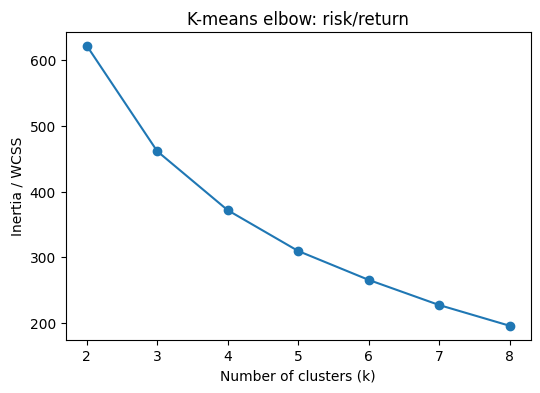

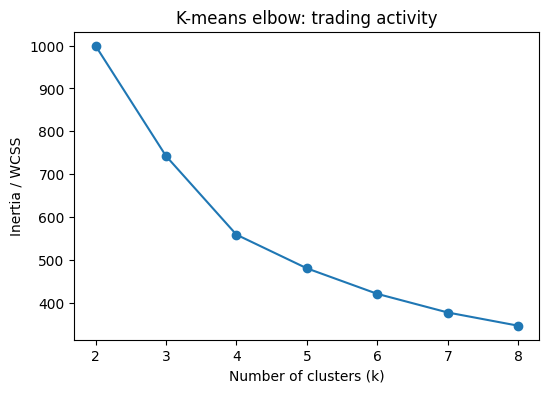

In [58]:
plt.figure(figsize=(6, 4))
plt.plot(km_risk_table.index, km_risk_table["Inertia"], marker="o")
plt.title("K-means elbow: risk/return")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia / WCSS")
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(km_activity_table.index, km_activity_table["Inertia"], marker="o")
plt.title("K-means elbow: trading activity")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia / WCSS")
plt.show()

In [59]:
km_k_risk = 5
km_k_activity = 2

km_risk_model = KMeans(n_clusters=km_k_risk, random_state=42, n_init=10)
km_risk_model.fit(risk_scaled)
features["KM_risk"] = km_risk_model.labels_

km_activity_model = KMeans(n_clusters=km_k_activity, random_state=42, n_init=10)
km_activity_model.fit(activity_scaled)
features["KM_activity"] = km_activity_model.labels_

def km_profile(label_col, cols):
    prof = display_features[cols].copy()
    prof["Cluster"] = features[label_col]
    rules = {}
    for col in cols:
        rules[col] = "median"
    out = prof.groupby("Cluster").agg(rules).round(2)
    out["Size"] = prof.groupby("Cluster")[cols[0]].count()
    return out

print(f"K-means risk/return, k = {km_k_risk} (return in %):")
print(km_profile("KM_risk", risk_cols), "\n")
print(f"K-means trading activity, k = {km_k_activity} (Recency in days, Monetary in USD bn):")
print(km_profile("KM_activity", activity_cols))

K-means risk/return, k = 5 (return in %):
         Mean_weekly_return  Beta  Size
Cluster                                
0                      0.07  1.03   112
1                      0.42  1.00   166
2                      0.20  0.53   131
3                      0.83  1.45    27
4                      0.27  1.54    50 

K-means trading activity, k = 2 (Recency in days, Monetary in USD bn):
         Recency  Frequency  Monetary  Size
Cluster                                    
0           11.0        3.0     15.26   384
1           49.0        2.0     21.18   102


## 2.4 Cluster profiles and algorithm comparison

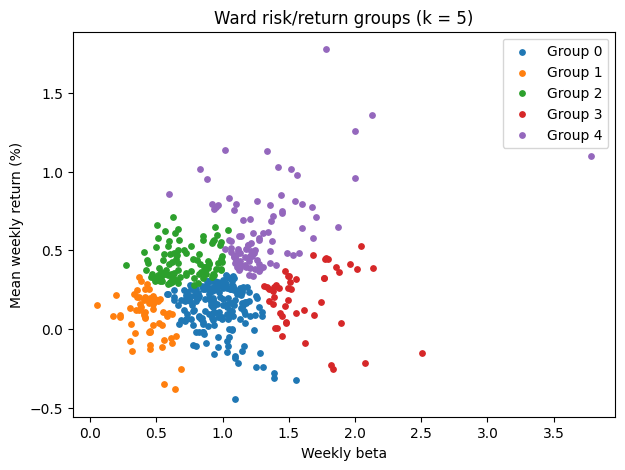

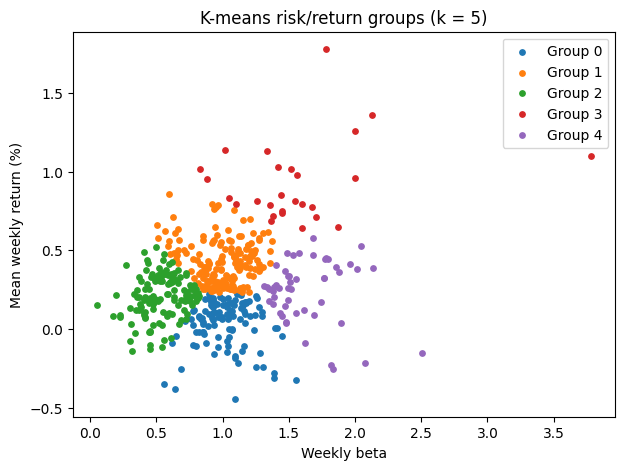

In [60]:
display_features["Ward_risk"] = features["Ward_risk"]
display_features["KM_risk"] = features["KM_risk"]

for label_col, method in [("Ward_risk", "Ward"), ("KM_risk", "K-means")]:
    plt.figure(figsize=(7, 5))
    for cluster, group in display_features.groupby(label_col):
        plt.scatter(group["Beta"], group["Mean_weekly_return"], s=15, label=f"Group {cluster}")
    plt.xlabel("Weekly beta")
    plt.ylabel("Mean weekly return (%)")
    plt.title(f"{method} risk/return groups (k = 5)")
    plt.legend()
    plt.show()

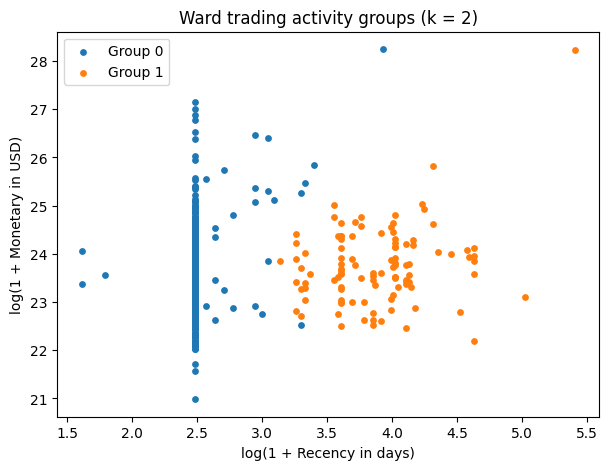

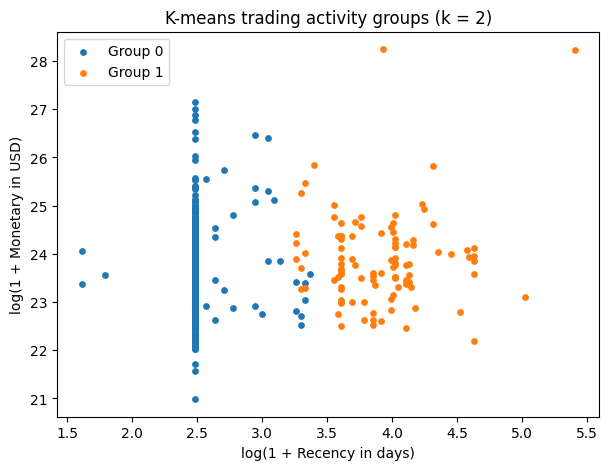

In [61]:
plot_activity = activity_t.copy()
plot_activity["Ward_activity"] = features["Ward_activity"]
plot_activity["KM_activity"] = features["KM_activity"]

for label_col, method in [("Ward_activity", "Ward"), ("KM_activity", "K-means")]:
    plt.figure(figsize=(7, 5))
    for cluster, group in plot_activity.groupby(label_col):
        plt.scatter(group["Recency"], group["Monetary"], s=15, label=f"Group {cluster}")
    plt.xlabel("log(1 + Recency in days)")
    plt.ylabel("log(1 + Monetary in USD)")
    plt.title(f"{method} trading activity groups (k = 2)")
    plt.legend()
    plt.show()

In [62]:
print("Risk/return: shares in each Ward group (rows) and K-means group (columns):")
print(features.groupby(["Ward_risk", "KM_risk"]).agg({"Beta": "count"}).rename(columns={"Beta": "Shares"}))

print("\nTrading activity: shares in each Ward group and K-means group:")
print(features.groupby(["Ward_activity", "KM_activity"]).agg({"Recency": "count"}).rename(columns={"Recency": "Shares"}))

Risk/return: shares in each Ward group (rows) and K-means group (columns):
                   Shares
Ward_risk KM_risk        
0         0           104
          1            49
          2            29
1         0             5
          2            61
2         1            57
          2            41
3         0             3
          4            45
4         1            60
          3            27
          4             5

Trading activity: shares in each Ward group and K-means group:
                           Shares
Ward_activity KM_activity        
0             0               376
              1                 4
1             0                 8
              1                98


## 2.5 RFM sensitivity and correlated inputs

### 2.5.1 Correlation analysis

In [63]:
corr_data = pd.DataFrame({
    "Recency": features["Recency"],
    "Frequency": features["Frequency"],
    "log1p(Monetary)": np.log1p(features["Monetary"])
})

print("Correlations among R, F and log1p(M) (as the brief asks):")
print(corr_data.corr().round(2))

print("\nCorrelations among the clustering inputs (log R, F, log M):")
print(activity_t.corr().round(2))

Correlations among R, F and log1p(M) (as the brief asks):
                 Recency  Frequency  log1p(Monetary)
Recency             1.00      -0.35             0.15
Frequency          -0.35       1.00             0.01
log1p(Monetary)     0.15       0.01             1.00

Correlations among the clustering inputs (log R, F, log M):
           Recency  Frequency  Monetary
Recency       1.00      -0.29      0.13
Frequency    -0.29       1.00      0.01
Monetary      0.13       0.01      1.00


### 2.5.2 Removal of Monetary

In [64]:
from sklearn.metrics import adjusted_rand_score

rf = activity_t[["Recency", "Frequency"]].copy()
rf_scaled = pd.DataFrame(StandardScaler().fit_transform(rf),
                         index=rf.index, columns=rf.columns)

ward_rf = linkage(rf_scaled, method="ward")
features["Ward_RF"] = cut_tree(ward_rf, n_clusters=ward_k_activity).ravel()

ari = adjusted_rand_score(features["Ward_activity"], features["Ward_RF"])
print("Shares:", len(features), "| k:", ward_k_activity)
print("Adjusted Rand index (with M vs without M):", round(ari, 3))

print("\nShares in each group (with M vs without M):")
print(features.groupby(["Ward_activity", "Ward_RF"]).agg({"Recency": "count"}).rename(columns={"Recency": "Shares"}))

Shares: 486 | k: 2
Adjusted Rand index (with M vs without M): 0.885

Shares in each group (with M vs without M):
                       Shares
Ward_activity Ward_RF        
0             0           372
              1             8
1             0             5
              1           101


In [65]:
display_features["Ward_activity"] = features["Ward_activity"]
display_features["Ward_RF"] = features["Ward_RF"]

rules = {"Recency": "median", "Frequency": "median", "Monetary": "median"}
for label_col, name in [("Ward_activity", "With M (R, F, M)"), ("Ward_RF", "Without M (R, F only)")]:
    out = display_features.groupby(label_col).agg(rules).round(2)
    out["Size"] = display_features.groupby(label_col)["Recency"].count()
    print(name, "(Recency in days, Monetary in USD bn):")
    print(out, "\n")

With M (R, F, M) (Recency in days, Monetary in USD bn):
               Recency  Frequency  Monetary  Size
Ward_activity                                    
0                 11.0        3.0     15.47   380
1                 46.5        2.0     19.49   106 

Without M (R, F only) (Recency in days, Monetary in USD bn):
         Recency  Frequency  Monetary  Size
Ward_RF                                    
0           11.0        3.0     15.33   377
1           46.0        2.0     20.85   109 



In [66]:
features.to_csv(f"{folder}/cluster_assignments.csv")

# Task 3: Business Intelligence and Critical Review

## Supporting analysis: sector composition of clusters (3.2.1)

In [67]:
clusters = pd.read_csv(f"{folder}/cluster_assignments.csv", index_col="Share")
print("Shares:", len(clusters))
print(clusters.columns.tolist())

Shares: 486
['Security', 'GICS Sector', 'Mean_weekly_return', 'Beta', 'Weeks', 'Last_event', 'Recency', 'Frequency', 'Monetary', 'Observation_date', 'Ward_risk', 'Ward_activity', 'KM_risk', 'KM_activity', 'Ward_RF']


In [68]:
for label_col, name in [("Ward_risk", "Ward risk/return (k = 5)"), ("Ward_activity", "Ward trading activity (k = 2)")]:
    counts = clusters.groupby([label_col, "GICS Sector"]).agg({"Beta": "count"}).rename(columns={"Beta": "Shares"})
    print(name, ": shares from each sector in each group")
    print(counts, "\n")

Ward risk/return (k = 5) : shares from each sector in each group
                                  Shares
Ward_risk GICS Sector                   
0         Communication Services       7
          Consumer Discretionary      17
          Consumer Staples             5
          Financials                  26
          Health Care                 25
          Industrials                 40
          Information Technology      20
          Materials                   14
          Real Estate                 23
          Utilities                    5
1         Communication Services       3
          Consumer Staples            22
          Financials                   2
          Health Care                 19
          Industrials                  2
          Materials                    1
          Real Estate                  1
          Utilities                   16
2         Communication Services       5
          Consumer Discretionary       9
          Consumer Staples       

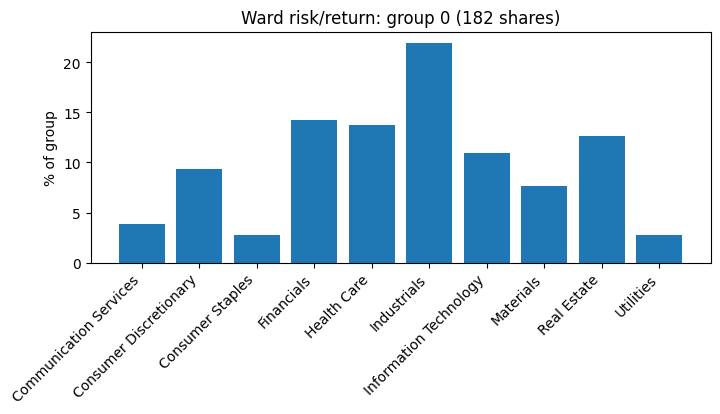

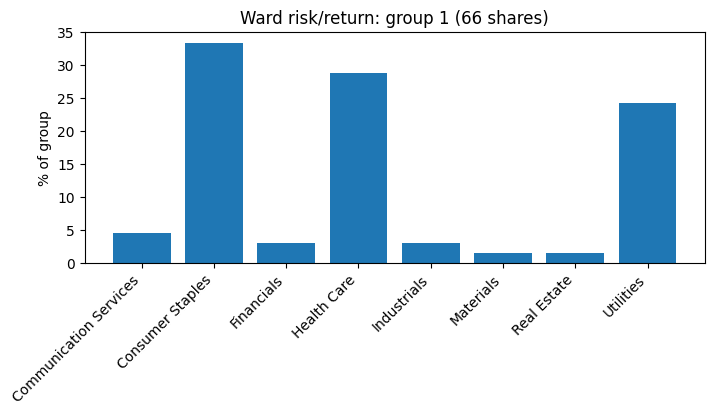

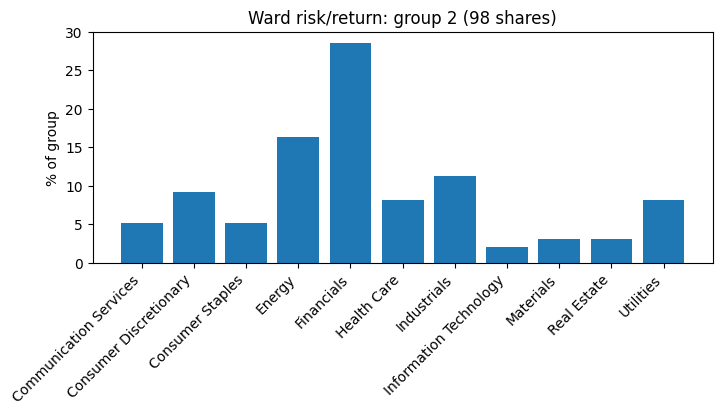

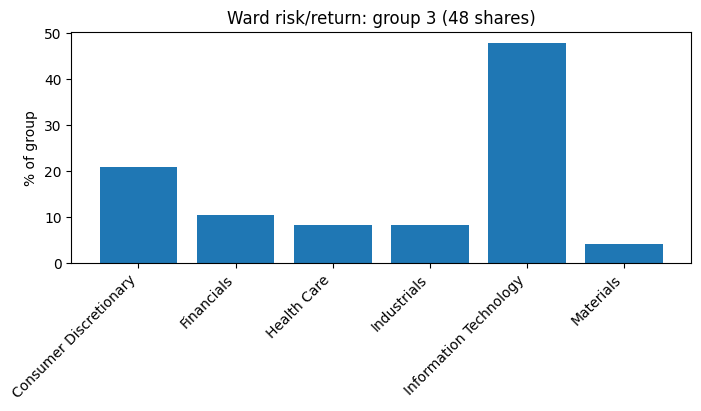

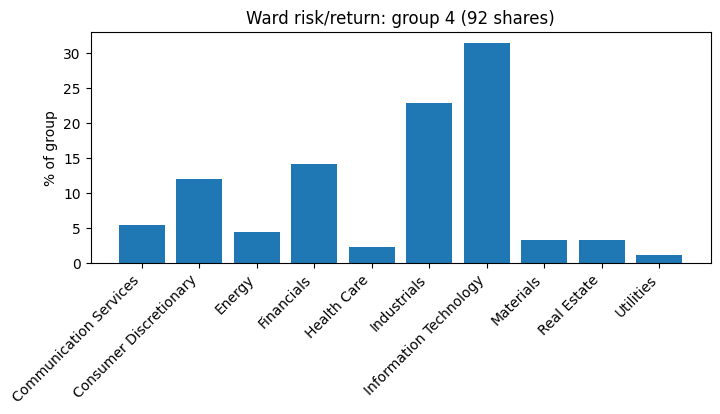

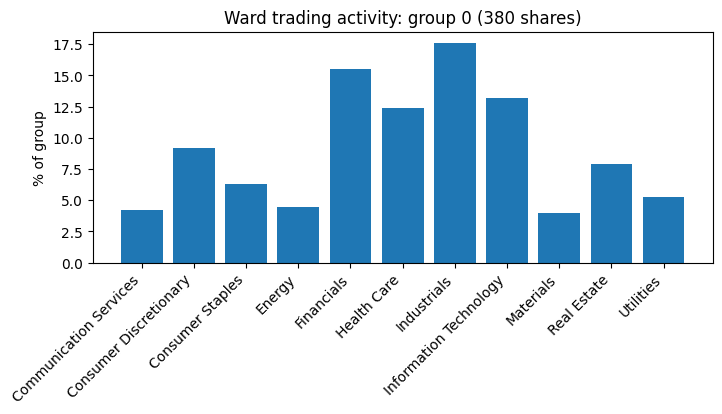

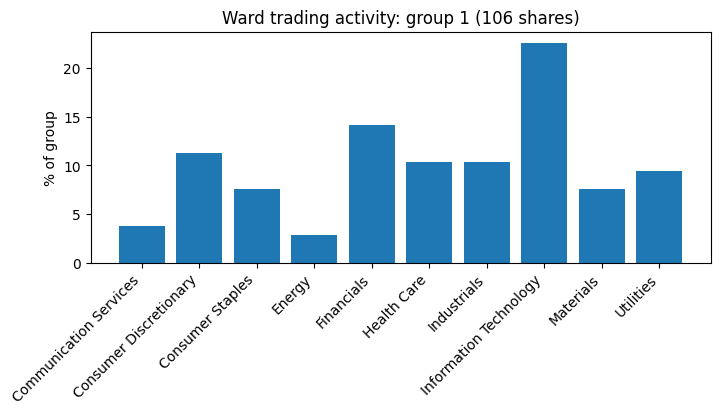

In [69]:
for label_col, name in [("Ward_risk", "Ward risk/return"), ("Ward_activity", "Ward trading activity")]:
    for cluster, group in clusters.groupby(label_col):
        counts = group.groupby("GICS Sector").agg({"Beta": "count"})["Beta"]
        pct = counts / len(group) * 100
        plt.figure(figsize=(8, 3))
        plt.bar(pct.index, pct.values)
        plt.xticks(rotation=45, ha="right")
        plt.ylabel("% of group")
        plt.title(f"{name}: group {cluster} ({len(group)} shares)")
        plt.show()